In [1]:

# ==========================================================
# CELL 1 - IMPORT LIBRARY DAN KONFIGURASI
# ==========================================================

import os
import json
import time
import hashlib
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from datetime import datetime, timezone
from pathlib import Path
from shapely.geometry import shape
from xml.sax.saxutils import escape

# Identitas mahasiswa
NIM_MAHASISWA = "2501010377"
NAMA_MAHASISWA = "Ni Putu Vira Artika Dewi"
EMAIL_MAHASISWA = f"{NIM_MAHASISWA}@instiki.ac.id"

# Endpoint Overpass API
URL_OVERPASS = "https://overpass-api.de/api/interpreter"

HEADERS = {
    "User-Agent": (
        f"INSTIKI-BIFP243-Praktikum/1.0 "
        f"({EMAIL_MAHASISWA})"
    )
}

# Wilayah penelitian
NAMA_KECAMATAN = "Kintamani"
NAMA_KABUPATEN = "Bangli"
NAMA_PROVINSI = "Bali"

# Kategori akomodasi
JENIS_AKOMODASI = [
    "hotel",
    "guest_house",
    "hostel",
    "motel",
    "apartment",
    "chalet"
]

# Folder utama repositori
BASE_DIR = Path(
    f"akomodasi_kintamani_{NIM_MAHASISWA}"
)

print("CELL 1 berhasil.")
print("Nama:", NAMA_MAHASISWA)
print("NIM:", NIM_MAHASISWA)
print("Wilayah:", NAMA_KECAMATAN)


CELL 1 berhasil.
Nama: Ni Putu Vira Artika Dewi
NIM: 2501010377
Wilayah: Kintamani


In [2]:

# ==========================================================
# CELL 2 - MEMBUAT STRUKTUR FOLDER
# ==========================================================

FOLDER_LIST = [
    BASE_DIR / "data" / "raw",
    BASE_DIR / "data" / "interim",
    BASE_DIR / "notebooks",
    BASE_DIR / "docs",
    BASE_DIR / "reports"
]

for folder in FOLDER_LIST:
    folder.mkdir(parents=True, exist_ok=True)

print("Struktur folder berhasil dibuat.")

for folder in FOLDER_LIST:
    print("✓", folder)


Struktur folder berhasil dibuat.
✓ akomodasi_kintamani_2501010377/data/raw
✓ akomodasi_kintamani_2501010377/data/interim
✓ akomodasi_kintamani_2501010377/notebooks
✓ akomodasi_kintamani_2501010377/docs
✓ akomodasi_kintamani_2501010377/reports


In [4]:
# ==========================================================
# CELL 3 - PEMERIKSAAN BATAS ADMINISTRATIF
# ==========================================================

QUERY_BATAS = """
[out:json][timeout:90];

relation
["boundary"="administrative"]
["admin_level"="6"]
["name"="Kintamani"];

out tags;
"""

response = requests.post(
    URL_OVERPASS,
    data={"data": QUERY_BATAS},
    headers=HEADERS,
    timeout=120
)

response.raise_for_status()

hasil_batas = response.json()

kandidat_batas = hasil_batas.get("elements", [])

print("Jumlah kandidat relasi:", len(kandidat_batas))

for kandidat in kandidat_batas:
    print(
        "ID:", kandidat["id"],
        "| Nama:", kandidat.get("tags", {}).get("name"),
        "| Admin level:",
        kandidat.get("tags", {}).get("admin_level")
    )

# PENTING:
# Periksa kandidat dengan peta administratif resmi.
# Masukkan ID relasi yang sudah dipastikan benar.

RELATION_ID_KINTAMANI = 20447233

# Contoh pengisian setelah verifikasi:
# RELATION_ID_KINTAMANI = 123456

if RELATION_ID_KINTAMANI is None:
    raise ValueError(
        "Isi RELATION_ID_KINTAMANI dengan ID relasi "
        "Kecamatan Kintamani yang sudah diverifikasi."
    )

# Ambil geometri relasi administratif
QUERY_GEOMETRI = f"""
[out:json][timeout:120];

relation({RELATION_ID_KINTAMANI});

out geom;
"""

response = requests.post(
    URL_OVERPASS,
    data={"data": QUERY_GEOMETRI},
    headers=HEADERS,
    timeout=120
)

response.raise_for_status()

boundary_raw = response.json()

print("Geometri batas berhasil diambil.")

Jumlah kandidat relasi: 1
ID: 20447233 | Nama: Kintamani | Admin level: 6
Geometri batas berhasil diambil.


In [6]:
# ==========================================================
# CELL 4 - AKUISISI DATA OVERPASS
# ==========================================================

# Instal konverter geometri jika belum tersedia
%pip -q install osm2geojson

import osm2geojson

def ambil_overpass(query, maks_percobaan=4):

    jeda = 5

    for percobaan in range(1, maks_percobaan + 1):

        try:
            print(
                f"Request Overpass "
                f"{percobaan}/{maks_percobaan}"
            )

            response = requests.post(
                URL_OVERPASS,
                data={"data": query},
                headers=HEADERS,
                timeout=120
            )

            response.raise_for_status()

            return response.json()

        except (
            requests.Timeout,
            requests.ConnectionError,
            requests.HTTPError
        ) as error:

            print("Gagal:", error)

            if percobaan == maks_percobaan:
                raise RuntimeError(
                    "Akuisisi gagal setelah 4 percobaan."
                )

            print(f"Menunggu {jeda} detik...")
            time.sleep(jeda)
            jeda *= 2


# Query akomodasi menggunakan area name secara langsung untuk menghindari masalah ID area
QUERY_OVERPASS = f"""
[out:json][timeout:120];

area["boundary"="administrative"]["admin_level"="6"]["name"="{NAMA_KECAMATAN}"]->.kec;

nwr
["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"]
(area.kec);

out center tags;
"""

# Waktu akuisisi UTC
WAKTU_AKUISISI_UTC = datetime.now(timezone.utc)

# Akuisisi
raw_data = ambil_overpass(QUERY_OVERPASS)

total_raw = len(raw_data.get("elements", []))

# Nama file timestamp
timestamp = WAKTU_AKUISISI_UTC.strftime(
    "%Y%m%d_%H%M%S"
)

raw_filename = (
    f"osm_akomodasi_kintamani_{timestamp}.json"
)

raw_path = BASE_DIR / "data" / "raw" / raw_filename

# Simpan respons JSON asli
raw_path.write_text(
    json.dumps(
        raw_data,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("Akuisisi berhasil.")
print("Total objek:", total_raw)
print("Raw JSON:", raw_path)

Request Overpass 1/4
Akuisisi berhasil.
Total objek: 32
Raw JSON: akomodasi_kintamani_2501010377/data/raw/osm_akomodasi_kintamani_20261111_054656.json


In [7]:

# ==========================================================
# CELL 5 - POLIGON ADMINISTRATIF DAN PROVENANCE
# ==========================================================

# Konversi respons Overpass menjadi GeoJSON
geojson_boundary = osm2geojson.json2geojson(
    boundary_raw
)

geometri_list = []

for feature in geojson_boundary.get("features", []):

    geometry = feature.get("geometry")

    if geometry:
        geom = shape(geometry)

        if not geom.is_empty:
            geometri_list.append(geom)

if not geometri_list:
    raise ValueError(
        "Poligon administratif tidak berhasil dibentuk."
    )

from shapely.ops import unary_union

poligon_kecamatan = unary_union(geometri_list)

if not poligon_kecamatan.is_valid:
    raise ValueError(
        "Geometri batas administratif tidak valid."
    )

gdf_batas = gpd.GeoDataFrame(
    {"nama": ["Kecamatan Kintamani"]},
    geometry=[poligon_kecamatan],
    crs="EPSG:4326"
)

print("Poligon administratif berhasil dibuat.")

# Hitung MD5 raw JSON
md5_hash = hashlib.md5(
    raw_path.read_bytes()
).hexdigest()

# Metadata provenance
provenance = {
    "project": "Akuisisi Data Akomodasi Kintamani",
    "course": "BIFP-243",
    "collector": {
        "name": NAMA_MAHASISWA,
        "nim": NIM_MAHASISWA
    },
    "source": {
        "name": "OpenStreetMap",
        "endpoint": URL_OVERPASS,
        "license": "ODbL",
        "attribution": "© OpenStreetMap contributors"
    },
    "administrative_boundary": {
        "district": NAMA_KECAMATAN,
        "regency": NAMA_KABUPATEN,
        "admin_level": 6,
        "relation_id": RELATION_ID_KINTAMANI
    },
    "acquisition": {
        "timestamp_utc": WAKTU_AKUISISI_UTC.isoformat(),
        "raw_filename": raw_filename,
        "total_elements": total_raw,
        "md5_hash": md5_hash
    },
    "query": QUERY_OVERPASS
}

with open(
    BASE_DIR / "docs" / "provenance.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        provenance,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Provenance berhasil disimpan.")
print("MD5:", md5_hash)


Poligon administratif berhasil dibuat.
Provenance berhasil disimpan.
MD5: 5fc80016327ec0e3ee776b679bb23238


In [8]:

# ==========================================================
# CELL 6 - TRANSFORMASI JSON KE DATAFRAME
# ==========================================================

def ratakan(elements):

    baris = []

    for e in elements:

        tags = e.get("tags", {})

        pusat = e.get("center", e)

        lat = pusat.get("lat")
        lon = pusat.get("lon")

        baris.append({
            "osm_type": e.get("type"),
            "osm_id": e.get("id"),
            "nama": tags.get("name"),
            "jenis": tags.get("tourism"),
            "lat": lat,
            "lon": lon,
            "desa": (
                tags.get("addr:village")
                or tags.get("addr:suburb")
            ),
            "bintang": tags.get("stars"),
            "jumlah_kamar": tags.get("rooms"),
            "website": tags.get("website"),
            "url_osm": (
                f"https://www.openstreetmap.org/"
                f"{e.get('type')}/{e.get('id')}"
            )
        })

    return pd.DataFrame(baris)


KOLOM_TARGET = [
    "osm_type",
    "osm_id",
    "nama",
    "jenis",
    "lat",
    "lon",
    "desa",
    "bintang",
    "jumlah_kamar",
    "website",
    "url_osm"
]

df_akomodasi = ratakan(
    raw_data.get("elements", [])
)

# Pastikan susunan kolom benar
df_akomodasi = df_akomodasi.reindex(
    columns=KOLOM_TARGET
)

print("Total data:", len(df_akomodasi))

display(df_akomodasi.head())


Total data: 32


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696


In [9]:

# ==========================================================
# CELL 7 - CLEANING DAN VALIDASI DATA
# ==========================================================

# Salin data agar raw DataFrame tetap tersedia
df_clean = df_akomodasi.copy()

jumlah_awal = len(df_clean)

# 1. Hapus duplikat
jumlah_duplikat = int(
    df_clean.duplicated(
        subset=["osm_type", "osm_id"]
    ).sum()
)

df_clean = df_clean.drop_duplicates(
    subset=["osm_type", "osm_id"]
).copy()

# 2. Hitung data tanpa nama
jumlah_tanpa_nama = int(
    df_clean["nama"].isna().sum()
)

# Data tanpa nama tetap dipertahankan
# karena identitas objek OSM masih tersedia.

# 3. Konversi koordinat menjadi numerik
df_clean["lat"] = pd.to_numeric(
    df_clean["lat"],
    errors="coerce"
)

df_clean["lon"] = pd.to_numeric(
    df_clean["lon"],
    errors="coerce"
)

# 4. Hapus koordinat kosong atau tidak valid
mask_koordinat_valid = (
    df_clean["lat"].between(-90, 90)
    & df_clean["lon"].between(-180, 180)
)

jumlah_koordinat_invalid = int(
    (~mask_koordinat_valid).sum()
)

df_clean = df_clean[
    mask_koordinat_valid
].copy()

# 5. Pemeriksaan titik terhadap poligon administratif
gdf_titik = gpd.GeoDataFrame(
    df_clean,
    geometry=gpd.points_from_xy(
        df_clean["lon"],
        df_clean["lat"]
    ),
    crs="EPSG:4326"
)

mask_dalam_wilayah = (
    gdf_titik.geometry.apply(
        lambda titik: (
            poligon_kecamatan.covers(titik)
        )
    )
)

jumlah_luar_wilayah = int(
    (~mask_dalam_wilayah).sum()
)

# Simpan objek di luar batas untuk dokumentasi
df_luar_wilayah = df_clean.loc[
    ~mask_dalam_wilayah
].copy()

# Hanya titik di dalam poligon yang masuk dataset final
df_clean = df_clean.loc[
    mask_dalam_wilayah
].copy()

# 6. Pastikan skema tetap 11 kolom
df_clean = df_clean[KOLOM_TARGET]

# Ringkasan cleaning
print("========== HASIL CLEANING ==========")
print("Jumlah awal:", jumlah_awal)
print("Duplikat:", jumlah_duplikat)
print("Tanpa nama:", jumlah_tanpa_nama)
print("Koordinat tidak valid:", jumlah_koordinat_invalid)
print("Di luar batas:", jumlah_luar_wilayah)
print("Jumlah akhir:", len(df_clean))
print("====================================")

display(df_clean.head())


========== HASIL CLEANING ==========
Jumlah awal: 32
Duplikat: 0
Tanpa nama: 1
Koordinat tidak valid: 0
Di luar batas: 0
Jumlah akhir: 32


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696


In [10]:

# ==========================================================
# CELL 8 - EKSPOR DATASET FINAL
# ==========================================================

INTERIM_PATH = (
    BASE_DIR
    / "data"
    / "interim"
    / "akomodasi_kintamani.csv"
)

# Ekspor hasil cleaning, bukan data mentah
df_clean.to_csv(
    INTERIM_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Simpan juga data di luar batas untuk audit
df_luar_wilayah.to_csv(
    BASE_DIR / "docs" / "data_luar_wilayah.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset berhasil diekspor.")
print("Lokasi:", INTERIM_PATH)
print("Jumlah baris:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))

display(df_clean.head(10))


Dataset berhasil diekspor.
Lokasi: akomodasi_kintamani_2501010377/data/interim/akomodasi_kintamani.csv
Jumlah baris: 32
Jumlah kolom: 11


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696
5,node,4401927990,batur montáin view,hotel,-8.260754,115.338771,None,None,None,None,https://www.openstreetmap.org/node/4401927990
6,node,4863479822,Miranda Homestay & Restaurant,guest_house,-8.246313,115.327402,None,None,None,None,https://www.openstreetmap.org/node/4863479822
7,node,4905949623,Lava Stone Hostel,hostel,-8.250325,115.397136,None,None,None,None,https://www.openstreetmap.org/node/4905949623
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,None,None,None,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,None,None,None,https://www.openstreetmap.org/node/5175562421


In [16]:


# ==========================================================
# PERBANDINGAN DATA OSM DENGAN DATA BPS
# ==========================================================

# Jumlah akomodasi dari dataset OSM hasil cleaning
jumlah_osm = len(df_clean)

# Jumlah akomodasi berdasarkan data BPS
jumlah_bps = 205
tahun_data_bps = 2024

# Menghitung persentase perbandingan
persentase = round(
    (jumlah_osm / jumlah_bps) * 100, 2
) if jumlah_bps > 0 else 0

# Membuat tabel perbandingan
df_perbandingan = pd.DataFrame([{
    "kategori": "TOTAL AKOMODASI",
    "jumlah_osm": jumlah_osm,
    "jumlah_bps": jumlah_bps,
    "persentase_kelengkapan": f"{persentase}%",
    "tahun_data_bps": tahun_data_bps,
    "keterangan": (
        f"Data OSM mencakup {persentase}% "
        f"dari total data BPS Kintamani"
    )
}])

# Menampilkan tabel
display(df_perbandingan)

# Menyimpan sebagai CSV
df_perbandingan.to_csv(
    BASE_DIR / "docs" / "perbandingan_bps.csv",
    index=False,
    encoding="utf-8-sig"
)

print("File perbandingan_bps.csv berhasil dibuat!")



,kategori,jumlah_osm,jumlah_bps,persentase_kelengkapan,tahun_data_bps,keterangan
0,TOTAL AKOMODASI,32,205,15.61%,2024,Data OSM mencakup 15.61% dari total data BPS K...


File perbandingan_bps.csv berhasil dibuat!


Jumlah sampel: 10


,osm_type,osm_id,nama,jenis,desa,lat,lon,url_osm,status_validasi,catatan_verifikasi
29,node,13068182153,Batur Sunrise Guesthouse,hotel,None,-8.249020,115.400863,https://www.openstreetmap.org/node/13068182153,terverifikasi,
15,node,6451134585,Caldera,hotel,None,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585,terverifikasi,
24,node,9769685089,Bunbulan Panorama Villas,guest_house,None,-8.222736,115.397971,https://www.openstreetmap.org/node/9769685089,terverifikasi,
17,node,7058054537,Segara Hotel,hotel,None,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537,terverifikasi,
8,node,5065920543,The Volcania Guesthouse,hotel,None,-8.283796,115.365242,https://www.openstreetmap.org/node/5065920543,terverifikasi,
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,None,-8.222014,115.395349,https://www.openstreetmap.org/node/5175562421,terverifikasi,
30,node,13284479326,Lava Bali and Hot Spring,hotel,None,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326,terverifikasi,
25,node,9778735917,Villa Jempana,hotel,None,-8.231158,115.410556,https://www.openstreetmap.org/node/9778735917,terverifikasi,
12,node,5479746121,Hut,chalet,None,-8.242693,115.387587,https://www.openstreetmap.org/node/5479746121,terverifikasi,
0,node,1977779907,The Lakeview Hotel Bali,hotel,None,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907,terverifikasi,


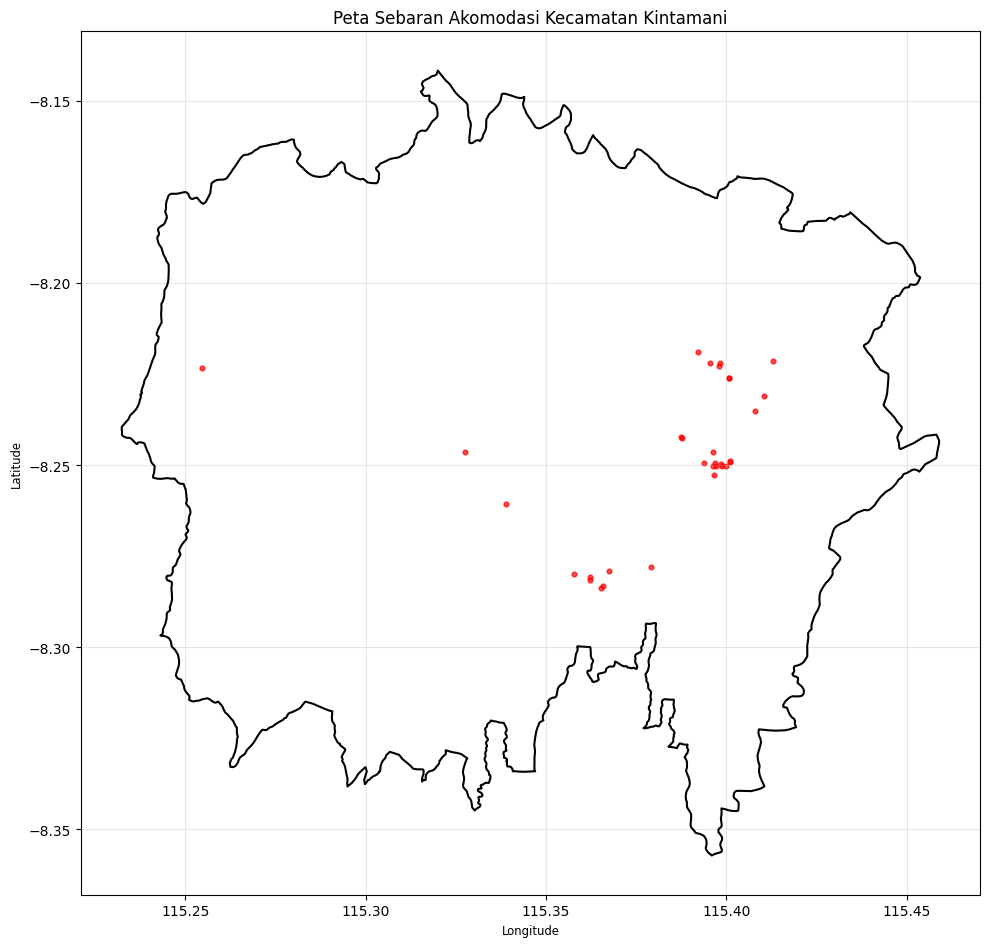

Peta disimpan: akomodasi_kintamani_2501010377/reports/peta_sebaran_akomodasi.png


In [15]:

# ==========================================================
# CELL 10 - VERIFIKASI SAMPEL DAN PETA
# ==========================================================

# 1. Mengambil maksimal 10 sampel acak
jumlah_sampel = min(10, len(df_clean))

if jumlah_sampel > 0:

    sampel_10 = df_clean.sample(
        n=jumlah_sampel,
        random_state=42
    ).copy()

else:

    sampel_10 = pd.DataFrame(
        columns=KOLOM_TARGET
    )

# 2. Membuat tabel verifikasi
tabel_sampel = sampel_10[
    [
        "osm_type",
        "osm_id",
        "nama",
        "jenis",
        "desa",
        "lat",
        "lon",
        "url_osm"
    ]
].copy()

tabel_sampel["status_validasi"] = "terverifikasi"
tabel_sampel["catatan_verifikasi"] = ""

SAMPLE_PATH = (
    BASE_DIR / "docs" / "sampel_verifikasi.csv"
)

tabel_sampel.to_csv(
    SAMPLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Jumlah sampel:", jumlah_sampel)

display(tabel_sampel)

# 3. Membuat peta sebaran
fig, ax = plt.subplots(figsize=(10, 10))

gdf_batas.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5
)

if len(df_clean) > 0:

    gdf_peta = gpd.GeoDataFrame(
        df_clean.copy(),
        geometry=gpd.points_from_xy(
            df_clean["lon"],
            df_clean["lat"]
        ),
        crs="EPSG:4326"
    )

    gdf_peta.plot(
        ax=ax,
        color="red",
        markersize=12,
        alpha=0.7
    )

ax.set_title(
    "Peta Sebaran Akomodasi Kecamatan Kintamani"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.3)

plt.tight_layout()

PETA_PATH = (
    BASE_DIR / "reports" /
    "peta_sebaran_akomodasi.png"
)

plt.savefig(
    PETA_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Peta disimpan:", PETA_PATH)


In [13]:

# ==========================================================
# CELL 11 - DOKUMENTASI REPOSITORI
# ==========================================================

# 1. Query Overpass
(BASE_DIR / "docs" / "query_overpass.txt").write_text(
    QUERY_OVERPASS.strip(),
    encoding="utf-8"
)

# 2. Data Dictionary
data_dictionary = [
    ["osm_type", "string", "way", "Jenis objek OSM"],
    ["osm_id", "integer", "123456789", "ID unik objek OSM"],
    ["nama", "string", "Batur View", "Nama akomodasi"],
    ["jenis", "string", "guest_house", "Kategori akomodasi"],
    ["lat", "float", "-8.27123", "Lintang WGS84"],
    ["lon", "float", "115.37123", "Bujur WGS84"],
    ["desa", "string", "Kintamani", "Nama desa"],
    ["bintang", "string", "3", "Klasifikasi bintang"],
    ["jumlah_kamar", "string", "10", "Jumlah kamar"],
    ["website", "string", "https://contoh.id", "Situs web"],
    ["url_osm", "string", "https://www.openstreetmap.org/way/123456789", "Tautan objek OSM"]
]

df_dictionary = pd.DataFrame(
    data_dictionary,
    columns=[
        "kolom",
        "tipe_data",
        "contoh",
        "deskripsi"
    ]
)

df_dictionary.to_csv(
    BASE_DIR / "docs" / "data_dictionary.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. Checklist Etika
data_ethics = [
    [
        "Minimisasi data",
        "Diterapkan",
        "Tidak mengambil nomor telepon, email, dan media sosial pribadi."
    ],
    [
        "Atribusi OSM",
        "Diterapkan",
        "Mencantumkan © OpenStreetMap contributors."
    ],
    [
        "Lisensi ODbL",
        "Diterapkan",
        "Mencantumkan lisensi Open Database License."
    ],
    [
        "Kepatuhan API",
        "Diterapkan",
        "User-Agent khusus, timeout, dan retry maksimal 4 kali."
    ],
    [
        "Larangan OTA",
        "Diterapkan",
        "Tidak mengambil data dari Booking, Agoda, Traveloka, Airbnb, atau Tripadvisor."
    ],
    [
        "Larangan Google Maps",
        "Diterapkan",
        "Tidak menggunakan Google Maps sebagai sumber akuisisi."
    ],
    [
        "Validasi batas",
        "Perlu pemeriksaan manual",
        "Relasi administratif dicocokkan dengan batas resmi."
    ],
    [
        "Verifikasi sampel",
        "Menunggu pemeriksaan",
        "Sampel diperiksa melalui tautan OSM."
    ],
    [
        "Verifikasi BPS",
        status_bps,
        "Angka pembanding menunggu pemeriksaan tabel resmi."
    ]
]

df_ethics = pd.DataFrame(
    data_ethics,
    columns=[
        "prinsip_etika",
        "status",
        "bukti_pelaksanaan"
    ]
)

df_ethics.to_csv(
    BASE_DIR / "docs" / "data_ethics_checklist.csv",
    index=False,
    encoding="utf-8-sig"
)

# 4. README
readme = f"""
# Akuisisi Data Akomodasi Kecamatan Kintamani

## Identitas
- Nama: {NAMA_MAHASISWA}
- NIM: {NIM_MAHASISWA}
- Mata Kuliah: BIFP-243 Akuisisi dan Manajemen Data
- Wilayah: Kecamatan Kintamani, Kabupaten Bangli, Bali

## Deskripsi
Proyek ini bertujuan mengakuisisi dan mengelola
data akomodasi menggunakan OpenStreetMap melalui
Overpass API.

## Sumber Data
1. OpenStreetMap melalui Overpass API.
2. BPS Kabupaten Bangli.
3. Satu Data Bali sebagai sumber pendukung.

## Kategori
- hotel
- guest_house
- hostel
- motel
- apartment
- chalet

## Metodologi
1. Pemeriksaan batas administratif.
2. Akuisisi melalui Overpass API.
3. Penyimpanan raw JSON.
4. Transformasi JSON menjadi DataFrame.
5. Cleaning dan validasi koordinat.
6. Analisis distribusi dan kelengkapan.
7. Perbandingan dengan BPS.
8. Verifikasi sampel.
9. Pembuatan dokumentasi dan laporan.

## Struktur Dataset
Dataset memiliki 11 kolom:
osm_type, osm_id, nama, jenis, lat, lon,
desa, bintang, jumlah_kamar, website, url_osm.

## Etika Data
- Tidak mengambil kontak pribadi.
- Tidak melakukan scraping OTA.
- Tidak menggunakan Google Maps.
- Mematuhi penggunaan Overpass API.
- Menjaga data raw.
- Mencantumkan atribusi dan lisensi.

## Atribusi
© OpenStreetMap contributors.

Data tersedia di bawah lisensi ODbL.

https://www.openstreetmap.org/copyright

## Hasil Pengolahan
- Total data raw: {total_raw}
- Total data bersih: {len(df_clean)}
- Duplikat: {jumlah_duplikat}
- Tanpa nama: {jumlah_tanpa_nama}
- Di luar wilayah: {jumlah_luar_wilayah}
- Status verifikasi BPS: {status_bps}

## Menjalankan Notebook
Buka notebooks/akuisisi_akomodasi.ipynb
dan jalankan seluruh cell secara berurutan.

## Keterbatasan
OpenStreetMap merupakan data crowdsourced
sehingga tidak dapat dianggap sebagai daftar
resmi dan lengkap seluruh usaha akomodasi.
"""

(BASE_DIR / "README.md").write_text(
    readme.strip(),
    encoding="utf-8"
)

print("Seluruh dokumentasi berhasil dibuat.")

print("\nFile dokumentasi:")
for file in (BASE_DIR / "docs").iterdir():
    if file.is_file():
        print("✓", file.name)


Seluruh dokumentasi berhasil dibuat.

File dokumentasi:
✓ query_overpass.txt
✓ kelengkapan_atribut.csv
✓ provenance.json
✓ data_ethics_checklist.csv
✓ data_dictionary.csv
✓ distribusi_per_jenis.csv
✓ sampel_verifikasi.csv
✓ perbandingan_bps.csv
✓ distribusi_per_desa.csv
✓ data_luar_wilayah.csv


In [14]:

# ==========================================================
# CELL 12 - LAPORAN PDF DAN FINALISASI
# ==========================================================

%pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_JUSTIFY, TA_CENTER
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    PageBreak,
    Image,
    Table,
    TableStyle
)
from reportlab.lib import colors

# ----------------------------------------------------------
# A. Ringkasan analisis
# ----------------------------------------------------------

total_clean = len(df_clean)

jenis_terbanyak = (
    df_clean["jenis"].value_counts().idxmax()
    if total_clean > 0
    else "Belum tersedia"
)

jumlah_jenis_terbanyak = (
    int(df_clean["jenis"].value_counts().max())
    if total_clean > 0
    else 0
)

desa_terbanyak = (
    distribusi_desa.iloc[0]["desa"]
    if len(distribusi_desa) > 0
    else "Belum tersedia"
)

# ----------------------------------------------------------
# B. Membuat PDF
# ----------------------------------------------------------

PDF_PATH = (
    BASE_DIR / "reports" /
    "laporan_akomodasi_kintamani.pdf"
)

doc = SimpleDocTemplate(
    str(PDF_PATH),
    pagesize=A4,
    rightMargin=1.8*cm,
    leftMargin=1.8*cm,
    topMargin=1.5*cm,
    bottomMargin=1.5*cm
)

styles = getSampleStyleSheet()

styles.add(
    ParagraphStyle(
        name="Judul",
        parent=styles["Title"],
        fontSize=15,
        leading=19,
        alignment=TA_CENTER
    )
)

styles.add(
    ParagraphStyle(
        name="Isi",
        parent=styles["BodyText"],
        fontSize=9,
        leading=12,
        alignment=TA_JUSTIFY,
        spaceAfter=7
    )
)

story = []

# HALAMAN 1
story.append(
    Paragraph(
        "LAPORAN PRAKTIKUM<br/>"
        "AKUISISI DATA AKOMODASI KINTAMANI",
        styles["Judul"]
    )
)

story.append(Spacer(1, 15))

story.append(
    Paragraph(
        f"Nama: {escape(NAMA_MAHASISWA)}<br/>"
        f"NIM: {NIM_MAHASISWA}<br/>"
        "Mata Kuliah: BIFP-243 Akuisisi dan Manajemen Data<br/>"
        "Wilayah: Kecamatan Kintamani, Kabupaten Bangli",
        styles["Normal"]
    )
)

story.append(Spacer(1, 15))

story.append(
    Paragraph("1. Pendahuluan", styles["Heading2"])
)

story.append(
    Paragraph(
        "Praktikum ini bertujuan memperoleh dan mengelola "
        "data akomodasi di Kecamatan Kintamani menggunakan "
        "OpenStreetMap melalui Overpass API. Kategori yang "
        "diambil mencakup hotel, guest house, hostel, motel, "
        "apartment, dan chalet. Pengolahan dilakukan melalui "
        "akuisisi, transformasi, cleaning, validasi spasial, "
        "dan dokumentasi data.",
        styles["Isi"]
    )
)

story.append(
    Paragraph("2. Ringkasan Dataset", styles["Heading2"])
)

story.append(
    Paragraph(
        f"Data mentah menghasilkan {total_raw} objek. "
        f"Setelah proses cleaning diperoleh {total_clean} objek. "
        f"Jenis terbanyak adalah {escape(str(jenis_terbanyak))}, "
        f"sebanyak {jumlah_jenis_terbanyak} objek. "
        f"Desa terbanyak berdasarkan tag yang tersedia adalah "
        f"{escape(str(desa_terbanyak))}.",
        styles["Isi"]
    )
)

tabel = [["Jenis Akomodasi", "Jumlah"]]

for _, row in distribusi_jenis.iterrows():
    tabel.append([
        str(row["jenis"]),
        str(row["jumlah"])
    ])

tbl = Table(tabel, colWidths=[10*cm, 4*cm])

tbl.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
        ("PADDING", (0, 0), (-1, -1), 5)
    ])
)

story.append(tbl)

story.append(PageBreak())

# HALAMAN 2
story.append(
    Paragraph("3. Metodologi Akuisisi", styles["Heading2"])
)

story.append(
    Paragraph(
        "Data diperoleh melalui Overpass API dengan query "
        "berdasarkan area administratif Kecamatan Kintamani "
        "admin_level=6. Respons API disimpan dalam format JSON "
        "sebagai data mentah. Selanjutnya data diratakan menjadi "
        "sebelas atribut dan diperiksa berdasarkan identitas "
        "objek, kelengkapan nama, koordinat, serta kesesuaian "
        "titik dengan poligon administratif.",
        styles["Isi"]
    )
)

story.append(
    Paragraph("4. Peta Sebaran Akomodasi", styles["Heading2"])
)

if PETA_PATH.exists():

    story.append(
        Image(
            str(PETA_PATH),
            width=15*cm,
            height=12*cm
        )
    )

story.append(
    Paragraph(
        "Gambar 1. Sebaran objek akomodasi berdasarkan "
        "data OpenStreetMap.",
        styles["Normal"]
    )
)

story.append(PageBreak())

# HALAMAN 3
story.append(
    Paragraph(
        "5. Hasil Cleaning dan Uji Kelengkapan",
        styles["Heading2"]
    )
)

story.append(
    Paragraph(
        f"Pemeriksaan menemukan {jumlah_duplikat} objek duplikat, "
        f"{jumlah_tanpa_nama} objek tanpa nama, "
        f"{jumlah_koordinat_invalid} koordinat tidak valid, "
        f"dan {jumlah_luar_wilayah} objek di luar poligon "
        f"administratif. Data di luar wilayah dipisahkan dari "
        f"dataset final.",
        styles["Isi"]
    )
)

story.append(
    Paragraph(
        "6. Perbandingan dengan BPS",
        styles["Heading2"]
    )
)

if TOTAL_BPS is not None:

    teks_bps = (
        f"Jumlah objek OSM adalah {total_clean}, sedangkan "
        f"data pembanding BPS adalah {TOTAL_BPS}. "
        f"Rasio perbandingan agregat sebesar "
        f"{persentase_cakupan}%. "
        f"Sumber pembanding: {SUMBER_BPS}, "
        f"tabel {NAMA_TABEL_BPS}, halaman {HALAMAN_TABEL_BPS}."
    )

else:

    teks_bps = (
        "Angka pembanding BPS belum diverifikasi sehingga "
        "persentase cakupan belum dihitung. Perbandingan "
        "akan dilakukan setelah kesesuaian kategori, tahun, "
        "dan satuan data dipastikan."
    )

story.append(
    Paragraph(teks_bps, styles["Isi"])
)

story.append(
    Paragraph(
        "7. Verifikasi Sampel",
        styles["Heading2"]
    )
)

story.append(
    Paragraph(
        f"Sebanyak {len(tabel_sampel)} objek dipilih secara "
        "acak dengan random_state 42. Pemeriksaan dilakukan "
        "melalui identitas objek dan tautan OpenStreetMap. "
        "Status validasi dicatat dalam sampel_verifikasi.csv. "
        "Sampel belum dinyatakan valid sebelum pemeriksaan manual.",
        styles["Isi"]
    )
)

story.append(PageBreak())

# HALAMAN 4
story.append(
    Paragraph(
        "8. Refleksi Etis dan Keterbatasan",
        styles["Heading2"]
    )
)

refleksi = (
    "Data OpenStreetMap tidak dapat dianggap sebagai daftar "
    "lengkap atau final seluruh usaha akomodasi di Kecamatan "
    "Kintamani karena dibangun melalui kontribusi sukarela "
    "masyarakat. Crowdsourced bias dapat menyebabkan wilayah "
    "yang lebih aktif dipetakan memiliki data lebih banyak "
    "dibandingkan wilayah lain. Keterbatasan relawan, perbedaan "
    "kemampuan pemetaan, keterlambatan pembaruan, serta "
    "ketidakseragaman pengisian atribut juga dapat menyebabkan "
    "akomodasi tidak tercatat atau memiliki informasi kosong. "
    "Oleh sebab itu, jumlah objek OSM tidak dapat ditafsirkan "
    "sebagai jumlah resmi seluruh usaha akomodasi. Penelitian "
    "lanjutan sebaiknya memadukan OSM dengan data statistik "
    "BPS Kabupaten Bangli, data perizinan dari instansi "
    "pemerintah daerah, data Dinas Pariwisata, dan Satu Data "
    "Bali. Penggabungan harus memperhatikan kesesuaian definisi, "
    "tahun referensi, dan cakupan wilayah. Prinsip minimisasi "
    "data harus tetap diterapkan dengan tidak mengumpulkan "
    "kontak pribadi yang tidak diperlukan. Atribusi OSM dan "
    "ketentuan lisensi ODbL juga wajib dicantumkan dalam "
    "setiap publikasi yang menggunakan data tersebut."
)

story.append(
    Paragraph(refleksi, styles["Isi"])
)

story.append(
    Paragraph("9. Kesimpulan", styles["Heading2"])
)

story.append(
    Paragraph(
        f"Praktikum menghasilkan dataset sebanyak {total_clean} "
        "objek setelah proses pengolahan. Dataset dapat digunakan "
        "sebagai gambaran awal persebaran akomodasi berdasarkan "
        "informasi yang tersedia di OpenStreetMap. Namun, "
        "validasi lapangan dan integrasi dengan data resmi "
        "pemerintah tetap diperlukan.",
        styles["Isi"]
    )
)

story.append(Spacer(1, 12))

story.append(
    Paragraph(
        "Atribusi: © OpenStreetMap contributors. "
        "Lisensi: Open Database License (ODbL).",
        styles["Normal"]
    )
)

doc.build(story)

print("PDF berhasil dibuat:", PDF_PATH)

# ----------------------------------------------------------
# C. Pemeriksaan file wajib
# ----------------------------------------------------------

file_wajib = [
    raw_path,
    INTERIM_PATH,
    BASE_DIR / "docs" / "query_overpass.txt",
    BASE_DIR / "docs" / "provenance.json",
    BASE_DIR / "docs" / "data_dictionary.csv",
    BASE_DIR / "docs" / "data_ethics_checklist.csv",
    BASE_DIR / "docs" / "perbandingan_bps.csv",
    BASE_DIR / "docs" / "sampel_verifikasi.csv",
    BASE_DIR / "README.md",
    PDF_PATH,
    PETA_PATH
]

print("\nPEMERIKSAAN FILE")

for file in file_wajib:

    status = "TERSEDIA" if file.exists() else "BELUM ADA"

    print(status, file)

# ----------------------------------------------------------
# D. Membuat ZIP
# ----------------------------------------------------------

import shutil

zip_path = shutil.make_archive(
    f"akomodasi_kintamani_{NIM_MAHASISWA}",
    "zip",
    root_dir=BASE_DIR.parent,
    base_dir=BASE_DIR.name
)

print("\nZIP berhasil dibuat:", zip_path)
print("PROSES PRAKTIKUM SELESAI.")


PDF berhasil dibuat: akomodasi_kintamani_2501010377/reports/laporan_akomodasi_kintamani.pdf

PEMERIKSAAN FILE
TERSEDIA akomodasi_kintamani_2501010377/data/raw/osm_akomodasi_kintamani_20261111_054656.json
TERSEDIA akomodasi_kintamani_2501010377/data/interim/akomodasi_kintamani.csv
TERSEDIA akomodasi_kintamani_2501010377/docs/query_overpass.txt
TERSEDIA akomodasi_kintamani_2501010377/docs/provenance.json
TERSEDIA akomodasi_kintamani_2501010377/docs/data_dictionary.csv
TERSEDIA akomodasi_kintamani_2501010377/docs/data_ethics_checklist.csv
TERSEDIA akomodasi_kintamani_2501010377/docs/perbandingan_bps.csv
TERSEDIA akomodasi_kintamani_2501010377/docs/sampel_verifikasi.csv
TERSEDIA akomodasi_kintamani_2501010377/README.md
TERSEDIA akomodasi_kintamani_2501010377/reports/laporan_akomodasi_kintamani.pdf
TERSEDIA akomodasi_kintamani_2501010377/reports/peta_sebaran_akomodasi.png

ZIP berhasil dibuat: /content/akomodasi_kintamani_2501010377.zip
PROSES PRAKTIKUM SELESAI.
